In [1]:
# Install Plotly
!pip install plotly -q

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots
from IPython.display import display

In [2]:
# Create a social media dataset

data = {

    "Post_ID": list(range(1, 31)),

    "Likes": [
        120, 250, 180, 400, 320,
        150, 500, 280, 350, 600,
        220, 450, 700, 380, 550,
        160, 300, 480, 650, 420,
        200, 520, 750, 330, 580,
        270, 620, 800, 390, 680
    ],

    "Shares": [
        20, 45, 30, 80, 60,
        25, 100, 50, 65, 120,
        35, 90, 140, 70, 110,
        28, 55, 95, 130, 85,
        40, 105, 150, 62, 115,
        48, 125, 160, 75, 135
    ],

    "Comments": [
        15, 30, 22, 55, 40,
        18, 65, 35, 45, 75,
        25, 60, 85, 48, 70,
        20, 38, 62, 80, 52,
        28, 68, 95, 42, 72,
        32, 78, 105, 50, 88
    ],

    "Platform": [
        "Instagram", "Facebook", "YouTube",
        "LinkedIn", "X", "Instagram",
        "Facebook", "YouTube", "LinkedIn",
        "X", "Instagram", "Facebook",
        "YouTube", "LinkedIn", "X",
        "Instagram", "Facebook", "YouTube",
        "LinkedIn", "X", "Instagram",
        "Facebook", "YouTube", "LinkedIn",
        "X", "Instagram", "Facebook",
        "YouTube", "LinkedIn", "X"
    ],

    "Post_Date": pd.date_range(
        start="2026-01-01",
        periods=30,
        freq="D"
    )
}

# Convert dictionary into DataFrame

df = pd.DataFrame(data)

# Display dataset

display(df)

,Post_ID,Likes,Shares,Comments,Platform,Post_Date
0,1,120,20,15,Instagram,2026-01-01
1,2,250,45,30,Facebook,2026-01-02
2,3,180,30,22,YouTube,2026-01-03
3,4,400,80,55,LinkedIn,2026-01-04
4,5,320,60,40,X,2026-01-05
5,6,150,25,18,Instagram,2026-01-06
6,7,500,100,65,Facebook,2026-01-07
7,8,280,50,35,YouTube,2026-01-08
8,9,350,65,45,LinkedIn,2026-01-09
9,10,600,120,75,X,2026-01-10


In [3]:
# 1. Check number of rows and columns

print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(30, 6)


In [4]:
# 2. Check column names and data types

print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Post_ID    30 non-null     int64         
 1   Likes      30 non-null     int64         
 2   Shares     30 non-null     int64         
 3   Comments   30 non-null     int64         
 4   Platform   30 non-null     object        
 5   Post_Date  30 non-null     datetime64[ns]
dtypes: datetime64[ns](1), int64(4), object(1)
memory usage: 1.5+ KB


In [5]:
# 3. Statistical summary

print("\nDescriptive Statistics:")
display(df.describe())



Descriptive Statistics:


,Post_ID,Likes,Shares,Comments,Post_Date
count,30.000000,30.000000,30.00000,30.000000,30
mean,15.500000,420.000000,81.60000,53.266667,2026-01-15 12:00:00
min,1.000000,120.000000,20.00000,15.000000,2026-01-01 00:00:00
25%,8.250000,272.500000,48.50000,32.750000,2026-01-08 06:00:00
50%,15.500000,395.000000,77.50000,51.000000,2026-01-15 12:00:00
75%,22.750000,572.500000,113.75000,71.500000,2026-01-22 18:00:00
max,30.000000,800.000000,160.00000,105.000000,2026-01-30 00:00:00
std,8.803408,192.604651,40.58843,24.734359,NaN


In [6]:
# 4. Frequency distribution of categorical column

print("\nPlatform-wise Post Count:")
print(df["Platform"].value_counts())


Platform-wise Post Count:
Platform
Instagram    6
Facebook     6
YouTube      6
LinkedIn     6
X            6
Name: count, dtype: int64


Social Media Correlation Matrix:


,Likes,Shares,Comments
Likes,1.000000,0.998817,0.997144
Shares,0.998817,1.000000,0.997570
Comments,0.997144,0.997570,1.000000


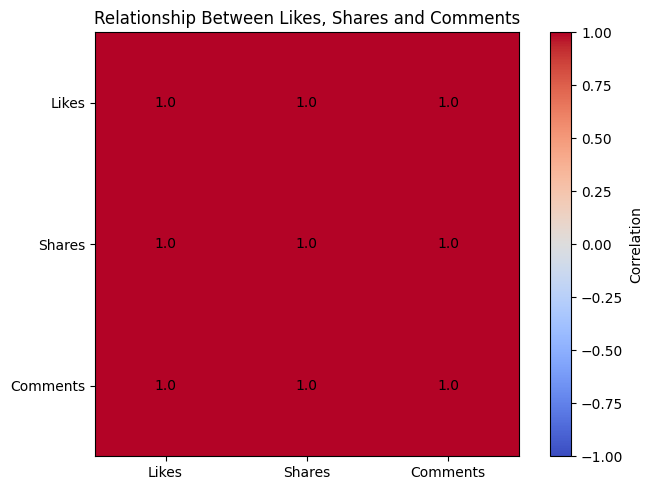

In [7]:
# Calculate correlation

correlation = df[
    ["Likes", "Shares", "Comments"]
].corr()

# Display correlation matrix

print("Social Media Correlation Matrix:")
display(correlation)


# Visualize correlation using a heatmap

plt.figure(figsize=(7, 5))

plt.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

# Display correlation values

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):

        plt.text(
            j, i,
            round(correlation.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.title("Relationship Between Likes, Shares and Comments")

plt.tight_layout()

plt.show()

In [8]:
# Calculate total engagement

df["Total_Engagement"] = (
    df["Likes"] +
    df["Shares"] +
    df["Comments"]
)


# Group posts by platform

platform_summary = df.groupby("Platform").agg(

    Average_Likes=("Likes", "mean"),

    Average_Shares=("Shares", "mean"),

    Average_Comments=("Comments", "mean"),

    Average_Engagement=("Total_Engagement", "mean"),

    Total_Engagement=("Total_Engagement", "sum"),

    Post_Count=("Post_ID", "count")

).round(2)


# Display platform-wise summary

print("Platform-wise Performance Summary:")

display(platform_summary)

Platform-wise Performance Summary:


,Average_Likes,Average_Shares,Average_Comments,Average_Engagement,Total_Engagement,Post_Count
Platform,,,,,,
Facebook,440.00,86.67,56.50,583.17,3499,6
Instagram,186.67,32.67,23.00,242.33,1454,6
LinkedIn,416.67,80.33,53.33,550.33,3302,6
X,525.00,104.17,66.17,695.33,4172,6
YouTube,531.67,104.17,67.33,703.17,4219,6


In [15]:
# Calculate platform-wise average engagement

platform_engagement = (
    df.groupby("Platform")["Total_Engagement"]
    .mean()
    .reset_index()
)


# Create a 2x2 dashboard

fig = make_subplots(

    rows=2,
    cols=2,

    subplot_titles=(

        "Likes and Comments Increase Together",

        "Average Engagement Across Platforms",

        "Distribution of Social Media Engagement",

        "Engagement Trends Across Posting Dates"

    ),

    vertical_spacing=0.16,

    horizontal_spacing=0.12
)


# CHART 1: Scatter Plot

fig.add_trace(

    go.Scatter(

        x=df["Likes"],

        y=df["Comments"],

        mode="markers",

        marker=dict(

            size=12,

            color=df["Shares"],

            colorscale="Viridis",

            showscale=True,

            colorbar=dict(title="Shares")

        ),

        text=df["Platform"],

        customdata=df[["Post_ID", "Shares"]],

        hovertemplate=

        "Platform: %{text}<br>" +

        "Post ID: %{customdata[0]}<br>" +

        "Likes: %{x}<br>" +

        "Comments: %{y}<br>" +

        "Shares: %{customdata[1]}<extra></extra>",

        name="Social Media Posts"

    ),

    row=1,

    col=1

)


# CHART 2: Bar Chart

fig.add_trace(

    go.Bar(

        x=platform_engagement["Platform"],

        y=platform_engagement["Total_Engagement"],

        text=platform_engagement[
            "Total_Engagement"
        ].round(1),

        textposition="outside",

        name="Average Engagement",

        hovertemplate=

        "Platform: %{x}<br>" +

        "Average Engagement: %{y:.2f}<extra></extra>"

    ),

    row=1,

    col=2

)


# CHART 3: Histogram

fig.add_trace(

    go.Histogram(

        x=df["Total_Engagement"],

        nbinsx=8,

        name="Engagement Distribution",

        hovertemplate=

        "Engagement Range: %{x}<br>" +

        "Number of Posts: %{y}<extra></extra>"

    ),

    row=2,

    col=1

)


# CHART 4: Line Chart

date_summary = df.sort_values("Post_Date")

fig.add_trace(

    go.Scatter(

        x=date_summary["Post_Date"],

        y=date_summary["Total_Engagement"],

        mode="lines+markers",

        marker=dict(size=8),

        name="Daily Engagement",

        hovertemplate=

        "Date: %{x|%d %b %Y}<br>" +

        "Total Engagement: %{y}<extra></extra>"

    ),

    row=2,

    col=2

)


# Axis labels

fig.update_xaxes(
    title_text="Likes",
    row=1,
    col=1
)

fig.update_yaxes(
    title_text="Comments",
    row=1,
    col=1
)

fig.update_xaxes(
    title_text="Platform",
    row=1,
    col=2
)

fig.update_yaxes(
    title_text="Average Engagement",
    row=1,
    col=2
)

fig.update_xaxes(
    title_text="Total Engagement",
    row=2,
    col=1
)

fig.update_yaxes(
    title_text="Number of Posts",
    row=2,
    col=1
)

fig.update_xaxes(
    title_text="Post Date",
    row=2,
    col=2
)

fig.update_yaxes(
    title_text="Total Engagement",
    row=2,
    col=2
)


# Dashboard title and layout

fig.update_layout(

    title=dict(

        text="SOCIAL MEDIA ENGAGEMENT AND CONTENT PERFORMANCE DASHBOARD",

        x=0.5,

        font=dict(size=20)

    ),

    height=850,

    width=1200,

    template="plotly_white",

    showlegend=True,

    hovermode="closest"

)


# Display interactive dashboard

fig.show()

In [16]:
# Export interactive dashboard

fig.write_html(

    "Social_Media_Engagement_Dashboard.html",

    include_plotlyjs=True

)

print("Dashboard exported successfully!")

Dashboard exported successfully!


In [17]:
from google.colab import files

files.download(
    "Social_Media_Engagement_Dashboard.html"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

# Calculate total engagement

df["Total_Engagement"] = (
    df["Likes"] +
    df["Shares"] +
    df["Comments"]
)

# Calculate platform-wise average engagement

platform_engagement = (
    df.groupby("Platform")["Total_Engagement"]
    .mean()
    .reset_index()
)

print("Platform engagement calculated successfully!")


Platform engagement calculated successfully!


In [13]:

# Find platform with highest average engagement

best_platform = platform_engagement.loc[
    platform_engagement["Total_Engagement"].idxmax()
]

# Find post with highest engagement

best_post = df.loc[
    df["Total_Engagement"].idxmax()
]

print("PROJECT FINDINGS")
print("-------------------------")

print(
    "Highest Average Engagement Platform:",
    best_platform["Platform"]
)

print(
    "Average Engagement:",
    best_platform["Total_Engagement"]
)

print(
    "Highest Performing Post ID:",
    best_post["Post_ID"]
)

print(
    "Highest Post Engagement:",
    best_post["Total_Engagement"]
)

print(
    "Total Number of Posts:",
    len(df)
)


PROJECT FINDINGS
-------------------------
Highest Average Engagement Platform: YouTube
Average Engagement: 703.1666666666666
Highest Performing Post ID: 28
Highest Post Engagement: 1065
Total Number of Posts: 30
